# RBF do Zero para Reconhecimento de Sílabas — Versão Experimental

## 1. Introdução e organização dos dados

**Objetivo.** Implementar do zero uma Rede Neural de Função de Base Radial (RBF) para reconhecimento silábico e entender *como o erro se comporta* variando os hiperparâmetros (número de centros, largura das gaussianas, taxa de aprendizado e regularização L2). Maximizar a acurácia **não** é o objetivo.

**Tarefa.** A rede classifica somente seis sílabas — `DI, REI, TA` (de DIREITA) e `ES, QUER, DA` (de ESQUERDA). As palavras completas são reconhecidas a posteriori por um verificador de sequência determinístico (`if/elif/else`) que lê as previsões individuais; não existe uma segunda rede para as palavras.

**Regras.** Apenas a biblioteca NumPy implementa a matemática da RBF (+ `scipy.io.wavfile` para ler arquivos WAV). Os centros das gaussianas serão encontrados via K-means manual. Os pesos da camada de saída serão treinados por gradiente descendente (Softmax e entropia cruzada) para possibilitar o acompanhamento do erro por época. Tudo feito à mão, sem bibliotecas prontas de Machine Learning. O Matplotlib e `IPython.display` servem exclusivamente para geração e exibição dos gráficos.

**Dados.** 423 sílabas WAV (16 kHz) já segmentadas, divididas **por gravação**: 318 treino / 63 validação / 42 teste (mesmas partições da atividade de MLP). A pasta `dados/` precisa estar no diretório de execução. O repositório original do projeto permanece intacto.

In [1]:
# ==============================================================================
# CONFIGURAÇÃO DE AMBIENTE: Detecção Google Colab / Execução Local
# ==============================================================================
import os, sys, subprocess

# Mantemos o mesmo repositório da MLP, pois os dados WAV e CSVs são idênticos
REPO_URL = "https://github.com/soaresgaab/reconhecimento-voz-mlp.git"

em_colab = "google.colab" in sys.modules

if em_colab:
    print("Ambiente detectado: Google Colab.")
    if not os.path.exists("dados/silabas.csv"):
        nome_pasta = REPO_URL.rstrip("/").split("/")[-1].replace(".git", "")
        if not os.path.exists(nome_pasta):
            if "SEU_USUARIO" in REPO_URL or not REPO_URL.startswith("https://github.com/") or REPO_URL.endswith("SEU_REPOSITORIO.git"):
                print("AVISO: Configure a variável REPO_URL com a URL pública do seu repositório GitHub para clonar os dados automaticamente.")
            else:
                print(f"Clonando repositório público via HTTPS: {REPO_URL} ...")
                subprocess.run(["git", "clone", "--depth", "1", REPO_URL], check=True)
        if os.path.exists(nome_pasta):
            os.chdir(nome_pasta)
            print(f"Diretório alterado para a raiz do projeto: {os.getcwd()}")
    else:
        print(f"Diretório do projeto já configurado: {os.getcwd()}")
else:
    print(f"Ambiente detectado: Execução Local ({sys.platform}).")
    while not os.path.exists("dados/silabas.csv") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")

if os.path.exists("dados/silabas.csv") and os.path.exists("dados/particoes.csv"):
    print("✔ Diretório do projeto configurado com sucesso!")
    print(f"  Raiz: {os.getcwd()}")
    print("  Arquivos 'dados/silabas.csv' e 'dados/particoes.csv' encontrados.")
else:
    print(f"✖ ATENÇÃO: Pasta 'dados/' não foi localizada a partir de {os.getcwd()}.")

Ambiente detectado: Execução Local (linux).
✔ Diretório do projeto configurado com sucesso!
  Raiz: /home/soaresgaab/Documentos/Mestrado UFMA/Disciplinas/Redes Neurais/Pipeline
  Arquivos 'dados/silabas.csv' e 'dados/particoes.csv' encontrados.


## 2. Preparação dos Dados e Auditoria das Partições

Nesta etapa, carregamos os metadados das sílabas e conferimos a divisão das partições (treinamento, validação e teste). Como as partições foram feitas por gravação completa, é fundamental garantir que a divisão original dos dados seja estritamente mantida. Isso assegura que a comparação retrospectiva com a MLP seja justa e válida.

In [2]:
# ==============================================================================
# LEITURA DOS METADADOS E AUDITORIA DAS PARTIÇÕES
# ==============================================================================
import os, csv
import numpy as np

CAMINHO_DADOS = "dados"
CAMINHO_SILABAS_CSV = os.path.join(CAMINHO_DADOS, "silabas.csv")
CAMINHO_PARTICOES_CSV = os.path.join(CAMINHO_DADOS, "particoes.csv")

CLASSES = ["DI", "REI", "TA", "ES", "QUER", "DA"]
CLASSE_ID = {c: i for i, c in enumerate(CLASSES)}
PARTICOES = ["treinamento", "validacao", "teste"]

# Carregar registros
with open(CAMINHO_SILABAS_CSV, encoding="utf-8") as f:
    registros = list(csv.DictReader(f))

# Contagem e auditoria
contagem = {c: {p: 0 for p in PARTICOES} for c in CLASSES}
for r in registros:
    contagem[r["classe"]][r["conjunto"]] += 1

print(f"{'Classe':<8}{'Treino':>8}{'Valid.':>8}{'Teste':>8}")
for c in CLASSES:
    print(f"{c:<8}{contagem[c]['treinamento']:>8}{contagem[c]['validacao']:>8}{contagem[c]['teste']:>8}")
print("-" * 34)
totais = {p: sum(contagem[c][p] for c in CLASSES) for p in PARTICOES}
print(f"{'Total':<8}{totais['treinamento']:>8}{totais['validacao']:>8}{totais['teste']:>8}   (= {sum(totais.values())} sílabas)")

# Garantir integridade histórica das partições
assert (totais["treinamento"], totais["validacao"], totais["teste"]) == (318, 63, 42), "Erro na quantidade de amostras das partições!"

Classe    Treino  Valid.   Teste
DI            51      10       7
REI           51      10       7
TA            51      10       7
ES            55      11       7
QUER          55      11       7
DA            55      11       7
----------------------------------
Total        318      63      42   (= 423 sílabas)


In [3]:
# ==============================================================================
# EXTRAÇÃO FFT E PADRONIZAÇÃO Z-SCORE (ZERO DATA LEAKAGE)
# ==============================================================================
from scipy.io import wavfile

def extrair_caracteristicas_fft(caminho_arquivo, n_bandas=16):
    taxa, audio = wavfile.read(caminho_arquivo)
    
    # Normalização do sinal de áudio
    sinal = audio.astype(np.float64) / 32768.0 if audio.dtype == np.int16 else audio.astype(np.float64)
    n = len(sinal)
    
    if n == 0:
        return np.zeros(n_bandas)
    
    espectro = np.fft.fft(sinal)
    n_meio = n // 2 + 1
    mag = np.abs(espectro[:n_meio]) / float(n)  # Espectro unilateral normalizado
    
    if n % 2 == 0:
        mag[1:-1] *= 2.0
    else:
        mag[1:] *= 2.0
        
    freq = np.linspace(0.0, taxa / 2.0, n_meio)
    largura = (taxa / 2.0) / n_bandas  # 500 Hz por banda
    
    carac = np.zeros(n_bandas)
    for b in range(n_bandas):
        lo, hi = b * largura, (b + 1) * largura
        idx = np.where((freq >= lo) & ((freq <= hi) if b == n_bandas - 1 else (freq < hi)))[0]
        carac[b] = np.mean(mag[idx]) if len(idx) > 0 else 0.0
        
    return carac

def caminho_silaba(r):
    return os.path.join(CAMINHO_DADOS, "silabas", r["classe"], r["arquivo_silaba"])

dados = {p: {"X": [], "y": [], "meta": []} for p in PARTICOES}

for r in registros:
    d = dados[r["conjunto"]]
    d["X"].append(extrair_caracteristicas_fft(caminho_silaba(r)))
    d["y"].append(CLASSE_ID[r["classe"]])
    d["meta"].append(r)

X_tr, y_tr = np.array(dados["treinamento"]["X"]), np.array(dados["treinamento"]["y"])
X_va, y_va = np.array(dados["validacao"]["X"]), np.array(dados["validacao"]["y"])
X_te, y_te = np.array(dados["teste"]["X"]), np.array(dados["teste"]["y"])

# PADRONIZAÇÃO EXCLUSIVA COM BASE NO TREINO
media_tr = X_tr.mean(axis=0, keepdims=True)
desvio_tr = X_tr.std(axis=0, keepdims=True)
desvio_tr[desvio_tr < 1e-12] = 1.0  # Evita divisão por zero

Xp_tr = (X_tr - media_tr) / desvio_tr
Xp_va = (X_va - media_tr) / desvio_tr
Xp_te = (X_te - media_tr) / desvio_tr

print("Dimensões finais (padronizadas):")
print(f"X_tr: {Xp_tr.shape} | y_tr: {y_tr.shape}")
print(f"X_va: {Xp_va.shape} | y_va: {y_va.shape}")
print(f"X_te: {Xp_te.shape} | y_te: {y_te.shape}")

Dimensões finais (padronizadas):
X_tr: (318, 16) | y_tr: (318,)
X_va: (63, 16) | y_va: (63,)
X_te: (42, 16) | y_te: (42,)


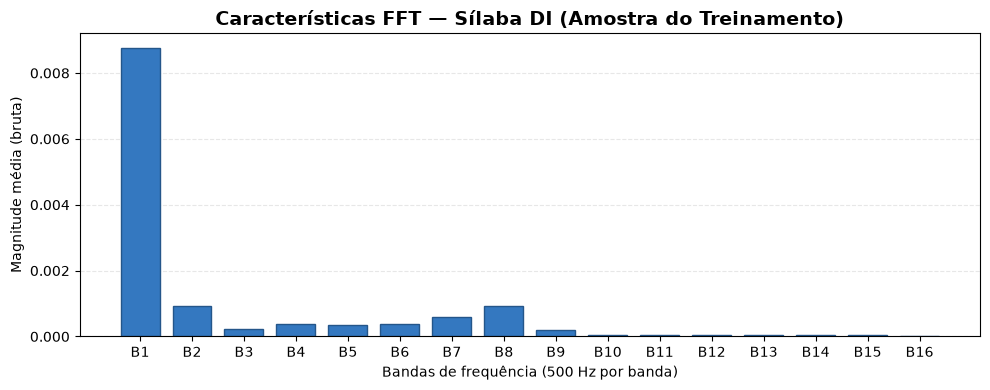

✔ Figura 1 exportada com sucesso para: figuras/rbf_figura1_fft.png


In [4]:
# ==============================================================================
# FIGURA 1: CARACTERÍSTICAS FFT (USANDO AMOSTRA BRUTA)
# ==============================================================================
import matplotlib.pyplot as plt
from pathlib import Path

# Captura os valores ANTES da padronização para exibir magnitudes reais
amostra_idx = np.where(y_tr == CLASSE_ID["DI"])[0][0]
valores_brutos = X_tr[amostra_idx]

fig, ax = plt.subplots(figsize=(10, 4))
bandas = np.arange(1, 17)

ax.bar(bandas, valores_brutos, color="#3478c0", edgecolor="#24568a", width=0.75)
ax.set_title("Características FFT — Sílaba DI (Amostra do Treinamento)", fontsize=14, fontweight="bold")
ax.set_xlabel("Bandas de frequência (500 Hz por banda)")
ax.set_ylabel("Magnitude média (bruta)")
ax.set_xticks(bandas)
ax.set_xticklabels([f"B{i}" for i in bandas])
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

fig.tight_layout()

# Salvamento automático e direto na pasta
pasta_figuras = Path("figuras")
pasta_figuras.mkdir(parents=True, exist_ok=True)
caminho_figura = pasta_figuras / "rbf_figura1_fft.png"
fig.savefig(caminho_figura, dpi=300, bbox_inches="tight")

plt.show()
plt.close(fig)
print(f"✔ Figura 1 exportada com sucesso para: {caminho_figura}")

## 3. Implementação Manual da RBF (K-Means e Gradiente Descendente)

Diferente da MLP, a Rede RBF possui um treinamento híbrido dividido em duas fases:
1. **Fase Não Supervisionada (Camada Oculta):** Os centros dos neurônios radiais são definidos pelo algoritmo **K-Means**, e o raio de alcance (espalhamento $\sigma$) é calculado heuristicamente. A ativação é dada por uma função Gaussiana baseada na distância Euclidiana entre a entrada e os centros.
2. **Fase Supervisionada (Camada de Saída):** Para permitir o acompanhamento do erro época a época e a avaliação de hiperparâmetros (como taxa de aprendizado e regularização L2), os pesos da camada de saída serão otimizados via **Gradiente Descendente (Otimizador Adam)** com função Softmax e Entropia Cruzada. 

Toda a matemática foi implementada do zero usando `numpy`, atendendo aos requisitos da disciplina.

In [5]:
# ==============================================================================
# FASE 1: K-MEANS MANUAL, CÁLCULO DE SIGMA E ATIVAÇÃO GAUSSIANA
# ==============================================================================
import numpy as np

def kmeans_manual(X, K, semente=42, max_iter=100):
    """Implementação do K-Means do zero para encontrar os centros da RBF."""
    rng = np.random.default_rng(semente)
    # Inicialização aleatória selecionando amostras do próprio conjunto
    indices = rng.choice(X.shape[0], K, replace=False)
    centros = X[indices].copy()
    
    for _ in range(max_iter):
        # Calcula a distância euclidiana de todos os pontos para todos os centros
        # X shape: (N, D), centros shape: (K, D) -> dists shape: (N, K)
        dists = np.linalg.norm(X[:, np.newaxis] - centros, axis=2)
        labels = np.argmin(dists, axis=1)
        
        novos_centros = np.zeros_like(centros)
        for k in range(K):
            pontos_k = X[labels == k]
            if len(pontos_k) > 0:
                novos_centros[k] = pontos_k.mean(axis=0)
            else:
                # Trata "neurônios mortos" reinicializando-os com um ponto aleatório
                novos_centros[k] = X[rng.choice(X.shape[0])]
                
        # Critério de parada: centros não mudaram
        if np.allclose(centros, novos_centros):
            break
        centros = novos_centros
        
    return centros

def calcular_sigma(centros):
    """Calcula o espalhamento (sigma) heurístico: distância média entre os centros."""
    K = centros.shape[0]
    if K <= 1: 
        return 1.0
    dists = np.linalg.norm(centros[:, np.newaxis] - centros, axis=2)
    # Soma todas as distâncias e divide pelo número de pares possíveis
    sigma = np.sum(dists) / (K * (K - 1))
    return sigma

def ativacao_rbf(X, centros, sigma):
    """Aplica a função gaussiana. Retorna a matriz H (saída da camada oculta)."""
    dists_sq = np.linalg.norm(X[:, np.newaxis] - centros, axis=2)**2
    return np.exp(-dists_sq / (2 * sigma**2))

print("✔ Funções da Fase 1 (K-Means e Gaussiana) implementadas com sucesso.")

✔ Funções da Fase 1 (K-Means e Gaussiana) implementadas com sucesso.


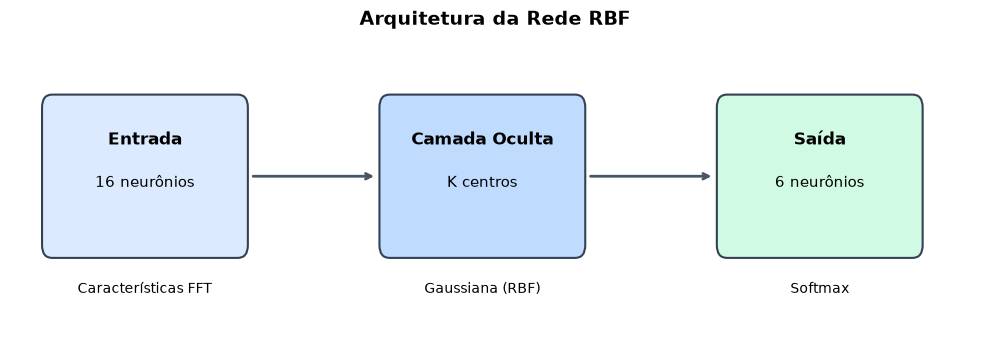

✔ Figura 2 exportada com sucesso para: figuras/rbf_figura2_arquitetura.png


In [6]:
# ==============================================================================
# FASE 2: FUNÇÕES DE SAÍDA E FIGURA 2 (ARQUITETURA DA REDE RBF)
# ==============================================================================
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from pathlib import Path

# Funções da Camada de Saída (Matemática Manual)
def softmax(Z):
    """Softmax com estabilidade numérica (subtrai o max)."""
    e = np.exp(Z - np.max(Z, axis=1, keepdims=True))
    return e / np.sum(e, axis=1, keepdims=True)

def entropia_cruzada(P, y, eps=1e-15):
    """Cálculo do loss (Entropia Cruzada) evitando log(0)."""
    Ps = np.clip(P, eps, 1.0 - eps)
    return -np.mean(np.log(Ps[np.arange(len(y)), y]))

def acuracia(P, y):
    """Calcula a taxa de acerto em porcentagem."""
    return 100.0 * np.mean(np.argmax(P, axis=1) == y)

# ------------------------------------------------------------------------------
# Geração da Figura 2: Arquitetura RBF
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 3.5))

camadas = [
    ("Entrada", 16, "Características FFT", "#dbeafe"),
    ("Camada Oculta", "K", "Gaussiana (RBF)", "#bfdbfe"),
    ("Saída", 6, "Softmax", "#d1fae5")
]
posicoes = [0.5, 4.5, 8.5]

for i, (nome, neuronios, funcao, cor) in enumerate(camadas):
    x = posicoes[i]
    caixa = FancyBboxPatch((x, 0.8), 2.2, 1.3, boxstyle="round,pad=0.12",
                           facecolor=cor, edgecolor="#334155", linewidth=1.5)
    ax.add_patch(caixa)
    
    ax.text(x + 1.1, 1.75, nome, ha="center", fontsize=12, fontweight="bold")
    texto_neuronios = f"{neuronios} neurônios" if isinstance(neuronios, int) else f"{neuronios} centros"
    ax.text(x + 1.1, 1.35, texto_neuronios, ha="center", fontsize=11)
    ax.text(x + 1.1, 0.35, funcao, ha="center", fontsize=10)
    
    if i < 2:
        ax.annotate("", xy=(posicoes[i+1] - 0.15, 1.45), xytext=(x + 2.35, 1.45),
                    arrowprops=dict(arrowstyle="->", lw=2, color="#475569"))

ax.set_xlim(0, 11.5)
ax.set_ylim(0, 2.8)
ax.axis("off")
ax.set_title("Arquitetura da Rede RBF", fontsize=14, fontweight="bold")

fig.tight_layout()

# Salvamento direto da Figura 2
pasta_figuras = Path("figuras")
caminho_figura = pasta_figuras / "rbf_figura2_arquitetura.png"
fig.savefig(caminho_figura, dpi=300, bbox_inches="tight")

plt.show()
plt.close(fig)
print(f"✔ Figura 2 exportada com sucesso para: {caminho_figura}")

## 4. Treinamento Inicial da Rede RBF

Nesta etapa, implementamos o ciclo completo de treinamento, que une o **K-Means** (para posicionamento dos centros radiais) e o **Gradiente Descendente** (para ajuste dos pesos da camada de saída linear).
A nossa **configuração de referência** será:
*   Número de centros ($K$): 16
*   Semente aleatória (*seed*): 42
*   Fator de espalhamento ($\sigma$): Baseado na distância média entre os centros (fator = 1.0)
*   Taxa de aprendizado ($\eta$): 0.010
*   Regularização L2 ($\lambda$): 0.0
*   Critério de parada (*Early Stopping*): Monitoramento da entropia cruzada no conjunto de validação, com paciência de 20 épocas.

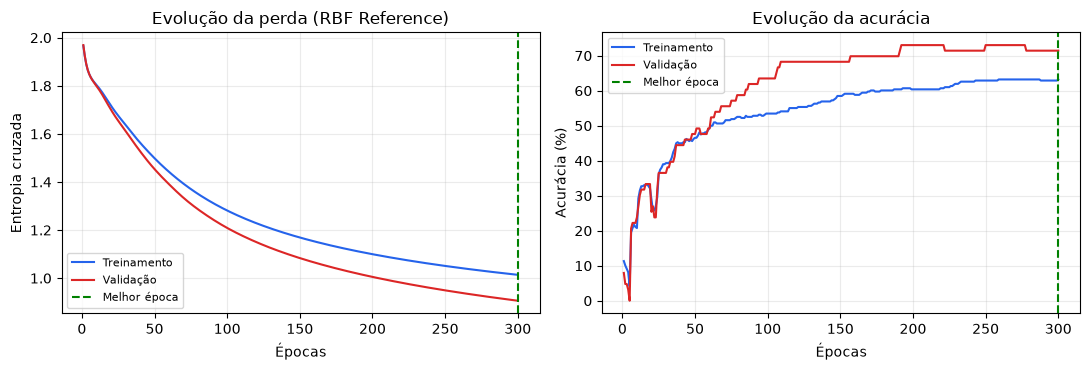

✔ Melhor época: 300 | Término: época 300 (Early Stopping)
Treino -> Perda: 1.0139 | Acc: 63.21%
Validação -> Perda: 0.9062 | Acc: 71.43%
Figura salva em: figuras/rbf_figura3_treino_inicial.png


In [7]:
# ==============================================================================
# TREINAMENTO DA SAÍDA POR GRADIENTE DESCENDENTE (ADAM) E FIGURA 3
# ==============================================================================

def treinar_rbf(X_tr, y_tr, X_va, y_va, K=16, fator_sigma=1.0, lr=0.01, 
                max_epocas=300, lam=0.0, paciencia=20, semente=42):
    
    # 1. Encontrar centros (K-Means) e Sigma
    centros = kmeans_manual(X_tr, K, semente)
    sigma = calcular_sigma(centros) * fator_sigma
    
    # 2. Feedforward Camada Oculta (Matrizes H - fixas durante o gradiente)
    H_tr = ativacao_rbf(X_tr, centros, sigma)
    H_va = ativacao_rbf(X_va, centros, sigma)
    
    # 3. Inicialização dos Pesos da Saída (K centros -> 6 classes)
    rng = np.random.default_rng(semente)
    W = rng.normal(0.0, np.sqrt(2.0/K), size=(K, 6))
    b = np.zeros((1, 6))
    
    # 4. Configuração Adam e Early Stopping
    m_W, v_W = np.zeros_like(W), np.zeros_like(W)
    m_b, v_b = np.zeros_like(b), np.zeros_like(b)
    beta1, beta2, eps_adam = 0.9, 0.999, 1e-8
    
    hist = {"perda_treino": [], "perda_val": [], "acc_treino": [], "acc_val": []}
    melhor_perda, melhor_epoca, sem_melhora = np.inf, 0, 0
    melhor_W, melhor_b = None, None
    N = len(y_tr)
    
    for ep in range(1, max_epocas + 1):
        # Forward Treino
        Z_tr = H_tr @ W + b
        P_tr = softmax(Z_tr)
        
        # Loss e Acc Treino
        perda_tr = entropia_cruzada(P_tr, y_tr) + 0.5 * lam * np.sum(W**2)
        hist["perda_treino"].append(perda_tr)
        hist["acc_treino"].append(acuracia(P_tr, y_tr))
        
        # Forward e Loss Validação
        Z_va = H_va @ W + b
        P_va = softmax(Z_va)
        perda_va = entropia_cruzada(P_va, y_va)  # Sem L2 para comparação justa
        hist["perda_val"].append(perda_va)
        hist["acc_val"].append(acuracia(P_va, y_va))
        
        # Early Stopping
        if melhor_perda - perda_va > 1e-5:
            melhor_perda = perda_va
            melhor_epoca = ep
            melhor_W, melhor_b = W.copy(), b.copy()
            sem_melhora = 0
        else:
            sem_melhora += 1
            if sem_melhora >= paciencia:
                break
                
        # Backpropagation (Gradiente)
        Y_one_hot = np.zeros_like(P_tr)
        Y_one_hot[np.arange(N), y_tr] = 1.0
        dZ = (P_tr - Y_one_hot) / N
        
        dW = H_tr.T @ dZ + lam * W
        db = np.sum(dZ, axis=0, keepdims=True)
        
        # Atualização Adam
        m_W = beta1 * m_W + (1 - beta1) * dW
        v_W = beta2 * v_W + (1 - beta2) * dW**2
        mW_hat = m_W / (1 - beta1**ep)
        vW_hat = v_W / (1 - beta2**ep)
        W -= lr * mW_hat / (np.sqrt(vW_hat) + eps_adam)
        
        m_b = beta1 * m_b + (1 - beta1) * db
        v_b = beta2 * v_b + (1 - beta2) * db**2
        mb_hat = m_b / (1 - beta1**ep)
        vb_hat = v_b / (1 - beta2**ep)
        b -= lr * mb_hat / (np.sqrt(vb_hat) + eps_adam)

    # Restaurar melhores pesos
    i = melhor_epoca - 1
    W, b = melhor_W, melhor_b
    
    return {"W": W, "b": b, "centros": centros, "sigma": sigma, "hist": hist, 
            "melhor_epoca": melhor_epoca, "epoca_final": ep,
            "val_final": {"perda": hist["perda_val"][i], "acc": hist["acc_val"][i], 
                          "perda_treino": hist["perda_treino"][i], "acc_treino": hist["acc_treino"][i]}}

# --- EXECUTAR O TREINO DE REFERÊNCIA ---
res_ref = treinar_rbf(Xp_tr, y_tr, Xp_va, y_va, K=16, fator_sigma=1.0, lr=0.010)

# --- PLOTAR A FIGURA 3 ---
ep_opt = res_ref["melhor_epoca"]
epocas = np.arange(1, len(res_ref["hist"]["perda_treino"]) + 1)

fig, eixos = plt.subplots(1, 2, figsize=(11, 3.8))

eixos[0].plot(epocas, res_ref["hist"]["perda_treino"], label="Treinamento", color="#2563eb")
eixos[0].plot(epocas, res_ref["hist"]["perda_val"], label="Validação", color="#dc2626")
eixos[0].axvline(ep_opt, color="green", linestyle="--", label="Melhor época")
eixos[0].set_title("Evolução da perda (RBF Reference)")
eixos[0].set_xlabel("Épocas")
eixos[0].set_ylabel("Entropia cruzada")
eixos[0].legend(fontsize=8)
eixos[0].grid(alpha=0.25)

eixos[1].plot(epocas, res_ref["hist"]["acc_treino"], label="Treinamento", color="#2563eb")
eixos[1].plot(epocas, res_ref["hist"]["acc_val"], label="Validação", color="#dc2626")
eixos[1].axvline(ep_opt, color="green", linestyle="--", label="Melhor época")
eixos[1].set_title("Evolução da acurácia")
eixos[1].set_xlabel("Épocas")
eixos[1].set_ylabel("Acurácia (%)")
eixos[1].legend(fontsize=8)
eixos[1].grid(alpha=0.25)

fig.tight_layout()

caminho_figura = Path("figuras") / "rbf_figura3_treino_inicial.png"
fig.savefig(caminho_figura, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

vf = res_ref["val_final"]
print(f"✔ Melhor época: {ep_opt} | Término: época {res_ref['epoca_final']} (Early Stopping)")
print(f"Treino -> Perda: {vf['perda_treino']:.4f} | Acc: {vf['acc_treino']:.2f}%")
print(f"Validação -> Perda: {vf['perda']:.4f} | Acc: {vf['acc']:.2f}%")
print(f"Figura salva em: {caminho_figura}")

## 5. Experimentos com Hiperparâmetros

Para compreender a dinâmica de aprendizagem da RBF, os hiperparâmetros serão inicialmente variados de forma isolada nos Grupos A a D, mantendo o restante da configuração de referência inalterada. Em seguida, o **Grupo E** investigará combinações simultâneas dos hiperparâmetros mais promissores. Cada configuração será treinada com **três sementes aleatórias (42, 43 e 44)** para garantir a estabilidade estatística dos resultados, reportando a média e o desvio padrão da perda de validação.

*   **Grupo A (Célula 12):** Número de Centros RBF ($K$) -> Analisa a capacidade de representação da rede.
*   **Grupo B (Célula 13):** Largura das Gaussianas ($\sigma$) -> Analisa a sensibilidade do campo receptivo aos padrões.
*   **Grupo C (Célula 14):** Taxa de Aprendizado ($lr$) -> Analisa a velocidade de convergência na camada de saída.
*   **Grupo D (Célula 15):** Regularização L2 ($\lambda$) -> Analisa o efeito da penalização para mitigar o *overfitting*.
*   **Grupo E (Célula 16):** Combinações de Hiperparâmetros -> Analisa interações conjuntas de capacidade ($K$), dispersão ($\sigma$) e taxa de convergência ($lr$).


Executando Grupo A: Variando a Capacidade (K centros)...


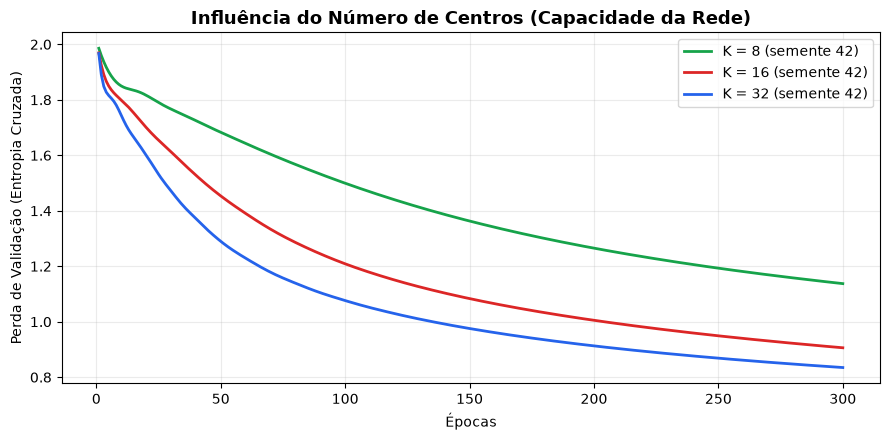

✔ Figura 4 exportada com sucesso para: figuras/rbf_figura4_centros.png
--------------------------------------------------
Resumo do Grupo A (Média de 3 sementes):
Config: K = 8   | Perda média val: 1.1398 ± 0.0100
Config: K = 16  | Perda média val: 0.9392 ± 0.0606
Config: K = 32  | Perda média val: 0.7956 ± 0.0454


In [8]:
# ==============================================================================
# EXPERIMENTOS GRUPO A: NÚMERO DE CENTROS RBF (K) E FIGURA 4
# ==============================================================================
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np

SEMENTES = (42, 43, 44)

def executar_experimento(valores_param, nome_param, kw_base):
    """Função auxiliar para testar diferentes valores de um hiperparâmetro com 3 sementes."""
    resultados = {}
    for val in valores_param:
        nome_config = f"{nome_param} = {val}"
        runs = []
        for s in SEMENTES:
            # Prepara os argumentos incluindo a semente atual
            kw_atual = kw_base.copy()
            kw_atual[nome_param] = val
            kw_atual["semente"] = s
            
            # Treina e armazena (preservando hiperparâmetros completos)
            res = treinar_rbf(Xp_tr, y_tr, Xp_va, y_va, **kw_atual)
            res["config"] = kw_atual.copy()
            runs.append(res)
        resultados[nome_config] = runs
    return resultados

# Configuração base inalterada (fator_sigma=1.0, lr=0.010, lam=0.0)
kw_base_A = {"fator_sigma": 1.0, "lr": 0.010, "lam": 0.0}
valores_K = [8, 16, 32] # Testando redes mais compactas e mais complexas

print("Executando Grupo A: Variando a Capacidade (K centros)...")
res_A = executar_experimento(valores_K, "K", kw_base_A)

# ------------------------------------------------------------------------------
# Geração da Figura 4
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 4.5))
cores = ["#16a34a", "#dc2626", "#2563eb"] # Verde (8), Vermelho (16), Azul (32)

for i, (nome, runs) in enumerate(res_A.items()):
    historico = runs[0]["hist"]  # Captura apenas a semente 42 para plotar a curva
    perdas = historico["perda_val"]
    epocas = range(1, len(perdas) + 1)
    ax.plot(epocas, perdas, label=f"{nome} (semente 42)", color=cores[i], linewidth=2)

ax.set_title("Influência do Número de Centros (Capacidade da Rede)", fontsize=13, fontweight="bold")
ax.set_xlabel("Épocas")
ax.set_ylabel("Perda de Validação (Entropia Cruzada)")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()

pasta_figuras = Path("figuras")
caminho_figura = pasta_figuras / "rbf_figura4_centros.png"
fig.savefig(caminho_figura, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"✔ Figura 4 exportada com sucesso para: {caminho_figura}")
print("-" * 50)
print("Resumo do Grupo A (Média de 3 sementes):")
for nome, runs in res_A.items():
    perdas_finais = [r["val_final"]["perda"] for r in runs]
    print(f"Config: {nome:<7} | Perda média val: {np.mean(perdas_finais):.4f} ± {np.std(perdas_finais, ddof=1):.4f}")


Executando Grupo B: Variando a Largura das Gaussianas (fator_sigma)...


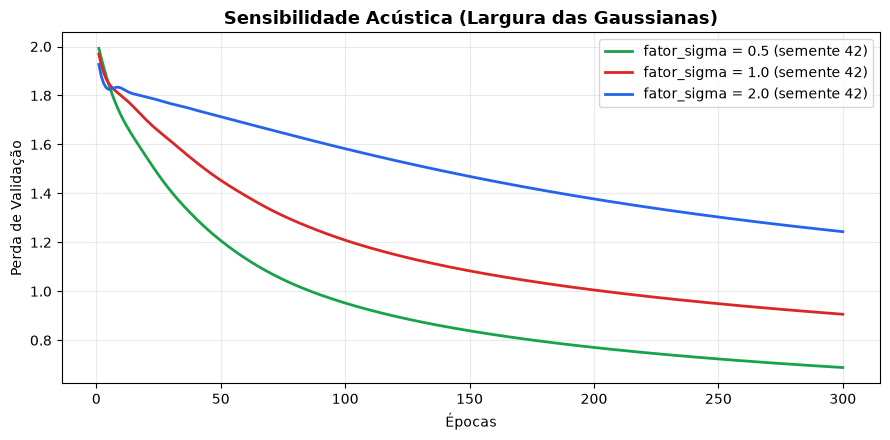

✔ Figura 5 exportada com sucesso para: figuras/rbf_figura5_sigma.png
--------------------------------------------------
Resumo do Grupo B (Média de 3 sementes):
Config: fator_sigma = 0.5  | Perda média val: 0.7021 ± 0.0304
Config: fator_sigma = 1.0  | Perda média val: 0.9392 ± 0.0606
Config: fator_sigma = 2.0  | Perda média val: 1.3169 ± 0.0775


In [9]:
# ==============================================================================
# EXPERIMENTOS GRUPO B: LARGURA DAS GAUSSIANAS (fator_sigma) E FIGURA 5
# ==============================================================================

# Vamos variar o multiplicador da distância média (fator_sigma)
kw_base_B = {"K": 16, "lr": 0.010, "lam": 0.0}
valores_sigma = [0.5, 1.0, 2.0] # Estreita (0.5), Padrão (1.0), Larga (2.0)

print("Executando Grupo B: Variando a Largura das Gaussianas (fator_sigma)...")
res_B = executar_experimento(valores_sigma, "fator_sigma", kw_base_B)

# ------------------------------------------------------------------------------
# Geração da Figura 5
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 4.5))
cores = ["#16a34a", "#dc2626", "#2563eb"]

for i, (nome, runs) in enumerate(res_B.items()):
    historico = runs[0]["hist"]
    perdas = historico["perda_val"]
    epocas = range(1, len(perdas) + 1)
    ax.plot(epocas, perdas, label=f"{nome} (semente 42)", color=cores[i], linewidth=2)

ax.set_title("Sensibilidade Acústica (Largura das Gaussianas)", fontsize=13, fontweight="bold")
ax.set_xlabel("Épocas")
ax.set_ylabel("Perda de Validação")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()

caminho_figura = pasta_figuras / "rbf_figura5_sigma.png"
fig.savefig(caminho_figura, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"✔ Figura 5 exportada com sucesso para: {caminho_figura}")
print("-" * 50)
print("Resumo do Grupo B (Média de 3 sementes):")
for nome, runs in res_B.items():
    perdas_finais = [r["val_final"]["perda"] for r in runs]
    print(f"Config: {nome:<18} | Perda média val: {np.mean(perdas_finais):.4f} ± {np.std(perdas_finais, ddof=1):.4f}")

Executando Grupo C: Variando a Taxa de Aprendizado (lr)...


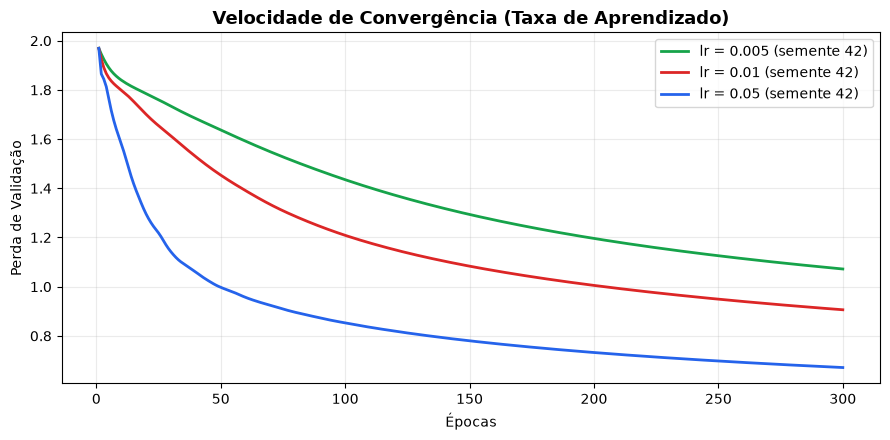

✔ Figura 6 exportada com sucesso para: figuras/rbf_figura6_lr.png
--------------------------------------------------
Resumo do Grupo C (Média de 3 sementes):
Config: lr = 0.005  | Perda média val: 1.1138 ± 0.0593
Config: lr = 0.01   | Perda média val: 0.9392 ± 0.0606
Config: lr = 0.05   | Perda média val: 0.6830 ± 0.0498


In [10]:
# ==============================================================================
# EXPERIMENTOS GRUPO C: TAXA DE APRENDIZADO (lr) E FIGURA 6
# ==============================================================================

kw_base_C = {"K": 16, "fator_sigma": 1.0, "lam": 0.0}
valores_lr = [0.005, 0.010, 0.050] # Lenta (0.005), Padrão (0.010), Rápida (0.050)

print("Executando Grupo C: Variando a Taxa de Aprendizado (lr)...")
res_C = executar_experimento(valores_lr, "lr", kw_base_C)

# ------------------------------------------------------------------------------
# Geração da Figura 6
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 4.5))
cores = ["#16a34a", "#dc2626", "#2563eb"]

for i, (nome, runs) in enumerate(res_C.items()):
    historico = runs[0]["hist"]
    perdas = historico["perda_val"]
    epocas = range(1, len(perdas) + 1)
    ax.plot(epocas, perdas, label=f"{nome} (semente 42)", color=cores[i], linewidth=2)

ax.set_title("Velocidade de Convergência (Taxa de Aprendizado)", fontsize=13, fontweight="bold")
ax.set_xlabel("Épocas")
ax.set_ylabel("Perda de Validação")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()

caminho_figura = pasta_figuras / "rbf_figura6_lr.png"
fig.savefig(caminho_figura, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"✔ Figura 6 exportada com sucesso para: {caminho_figura}")
print("-" * 50)
print("Resumo do Grupo C (Média de 3 sementes):")
for nome, runs in res_C.items():
    perdas_finais = [r["val_final"]["perda"] for r in runs]
    print(f"Config: {nome:<11} | Perda média val: {np.mean(perdas_finais):.4f} ± {np.std(perdas_finais, ddof=1):.4f}")

Executando Grupo D: Variando a Regularização L2 (lam)...


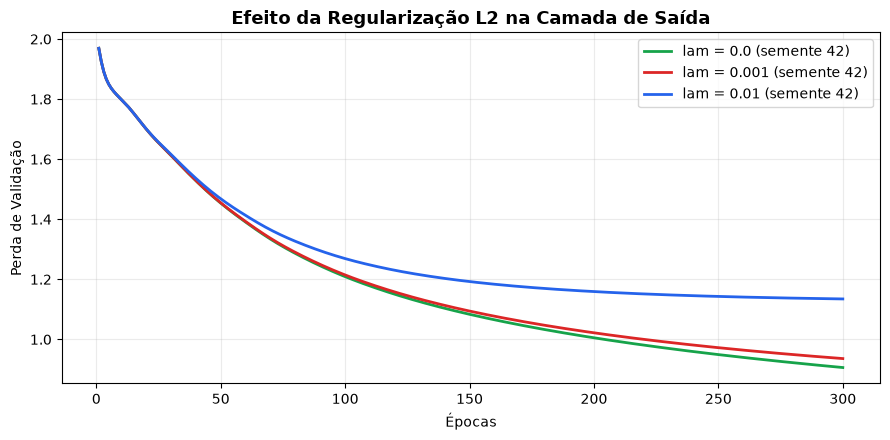

✔ Figura 7 exportada com sucesso para: figuras/rbf_figura7_regularizacao.png
--------------------------------------------------
Resumo do Grupo D (Média de 3 sementes):
Config: lam = 0.0    | Perda média val: 0.9392 ± 0.0606
Config: lam = 0.001  | Perda média val: 0.9681 ± 0.0508
Config: lam = 0.01   | Perda média val: 1.1487 ± 0.0186


In [11]:
# ==============================================================================
# EXPERIMENTOS GRUPO D: REGULARIZAÇÃO L2 (lam) E FIGURA 7
# ==============================================================================

kw_base_D = {"K": 16, "fator_sigma": 1.0, "lr": 0.010}
valores_lam = [0.0, 0.001, 0.01] # Sem penalidade (0), Leve (0.001), Forte (0.01)

print("Executando Grupo D: Variando a Regularização L2 (lam)...")
res_D = executar_experimento(valores_lam, "lam", kw_base_D)

# ------------------------------------------------------------------------------
# Geração da Figura 7
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 4.5))
cores = ["#16a34a", "#dc2626", "#2563eb"]

for i, (nome, runs) in enumerate(res_D.items()):
    historico = runs[0]["hist"]
    perdas = historico["perda_val"]
    epocas = range(1, len(perdas) + 1)
    ax.plot(epocas, perdas, label=f"{nome} (semente 42)", color=cores[i], linewidth=2)

ax.set_title("Efeito da Regularização L2 na Camada de Saída", fontsize=13, fontweight="bold")
ax.set_xlabel("Épocas")
ax.set_ylabel("Perda de Validação")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()

caminho_figura = pasta_figuras / "rbf_figura7_regularizacao.png"
fig.savefig(caminho_figura, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"✔ Figura 7 exportada com sucesso para: {caminho_figura}")
print("-" * 50)
print("Resumo do Grupo D (Média de 3 sementes):")
for nome, runs in res_D.items():
    perdas_finais = [r["val_final"]["perda"] for r in runs]
    print(f"Config: {nome:<12} | Perda média val: {np.mean(perdas_finais):.4f} ± {np.std(perdas_finais, ddof=1):.4f}")

Executando Grupo E: Combinações de Hiperparâmetros...


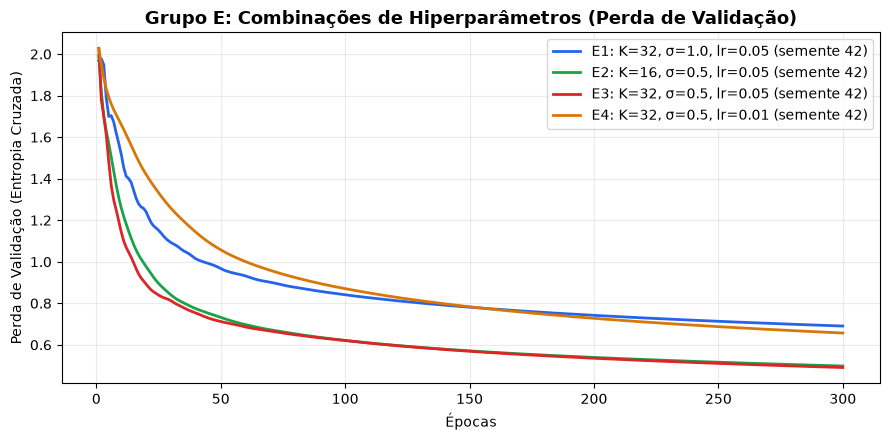

✔ Gráfico do Grupo E exportado com sucesso para: figuras/rbf_grupo_e_combinacoes.png
--------------------------------------------------
Resumo do Grupo E (Média de 3 sementes):
Config: E1: K=32, σ=1.0, lr=0.05     | Perda média val: 0.6234 ± 0.0639
Config: E2: K=16, σ=0.5, lr=0.05     | Perda média val: 0.5036 ± 0.0144
Config: E3: K=32, σ=0.5, lr=0.05     | Perda média val: 0.4375 ± 0.0506
Config: E4: K=32, σ=0.5, lr=0.01     | Perda média val: 0.6010 ± 0.0490


In [12]:
# ==============================================================================
# EXPERIMENTOS GRUPO E: COMBINAÇÕES DE HIPERPARÂMETROS E FIGURA GRUPO E
# ==============================================================================
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np

# Definição das quatro combinações investigadas
configs_E = {
    "E1: K=32, σ=1.0, lr=0.05": {"K": 32, "fator_sigma": 1.0, "lr": 0.05, "lam": 0.0},
    "E2: K=16, σ=0.5, lr=0.05": {"K": 16, "fator_sigma": 0.5, "lr": 0.05, "lam": 0.0},
    "E3: K=32, σ=0.5, lr=0.05": {"K": 32, "fator_sigma": 0.5, "lr": 0.05, "lam": 0.0},
    "E4: K=32, σ=0.5, lr=0.01": {"K": 32, "fator_sigma": 0.5, "lr": 0.01, "lam": 0.0}
}

print("Executando Grupo E: Combinações de Hiperparâmetros...")
res_E = {}

for nome, cfg in configs_E.items():
    runs = []
    for s in SEMENTES:
        kw_atual = cfg.copy()
        kw_atual["semente"] = s
        
        # Treina reutilizando treinar_rbf sem duplicar a implementação
        res = treinar_rbf(Xp_tr, y_tr, Xp_va, y_va, **kw_atual)
        res["config"] = kw_atual.copy()
        runs.append(res)
    res_E[nome] = runs

# ------------------------------------------------------------------------------
# Geração do Gráfico do Grupo E (Evolução da perda de validação - Semente 42)
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 4.5))
cores = ["#2563eb", "#16a34a", "#dc2626", "#d97706"]

for i, (nome, runs) in enumerate(res_E.items()):
    historico = runs[0]["hist"] # Semente 42 para a curva de perda
    perdas = historico["perda_val"]
    epocas = range(1, len(perdas) + 1)
    ax.plot(epocas, perdas, label=f"{nome} (semente 42)", color=cores[i], linewidth=2)

ax.set_title("Grupo E: Combinações de Hiperparâmetros (Perda de Validação)", fontsize=13, fontweight="bold")
ax.set_xlabel("Épocas")
ax.set_ylabel("Perda de Validação (Entropia Cruzada)")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()

pasta_figuras = Path("figuras")
pasta_figuras.mkdir(parents=True, exist_ok=True)
caminho_figura = pasta_figuras / "rbf_grupo_e_combinacoes.png"
fig.savefig(caminho_figura, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"✔ Gráfico do Grupo E exportado com sucesso para: {caminho_figura}")
print("-" * 50)
print("Resumo do Grupo E (Média de 3 sementes):")
for nome, runs in res_E.items():
    perdas_finais = [r["val_final"]["perda"] for r in runs]
    print(f"Config: {nome:<28} | Perda média val: {np.mean(perdas_finais):.4f} ± {np.std(perdas_finais, ddof=1):.4f}")


## 6. Comparação Final e Seleção do Modelo

Após avaliarmos isoladamente a capacidade da rede (Grupo A), a sensibilidade acústica (Grupo B), a velocidade de convergência (Grupo C), a penalização dos pesos (Grupo D) e as combinações de hiperparâmetros (Grupo E), vamos comparar as melhores configurações de cada grupo com o nosso modelo de referência (Baseline). 

O objetivo é selecionar a arquitetura que apresentou o menor erro de validação de forma estável (menor perda média entre as três sementes) para avançarmos para a fase final de avaliação retrospectiva no conjunto de teste e reconhecimento de palavras.


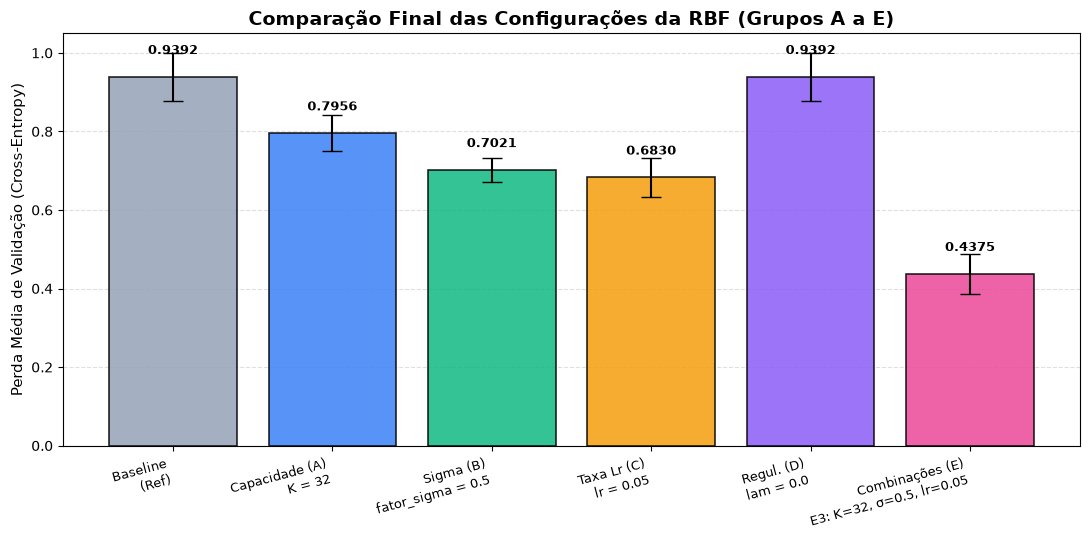

✔ Figura 8 exportada com sucesso para: figuras/rbf_figura8_comparacao_final.png
-----------------------------------------------------------------
CONCLUSÃO DA SELEÇÃO:
-> Configuração VENCEDORA selecionada para a Avaliação Final: Combinações (E) -> E3: K=32, σ=0.5, lr=0.05
   Hiperparâmetros completos:
     * K (número de centros): 32
     * fator_sigma (largura): 0.5
     * Taxa de aprendizado (lr): 0.05
     * Regularização L2 (lam): 0.0
   Perda Média de Validação: 0.4375 ± 0.0506
-> O dicionário 'modelo_final_selecionado' guardou a rede (semente 42) pronta para o teste.
-> NOTA: O conjunto de Teste permaneceu 100% isolado durante toda esta etapa (Zero Data Leakage).


In [13]:
# ==============================================================================
# COMPARAÇÃO FINAL, FIGURA 8 E SELEÇÃO DO MODELO VENCEDOR
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

def extrair_melhor(res_dict):
    """Encontra a configuração com a menor perda média dentro de um dicionário de resultados."""
    melhor_nome = None
    menor_perda = np.inf
    runs_melhor = None
    for nome, runs in res_dict.items():
        media = np.mean([r["val_final"]["perda"] for r in runs])
        if media < menor_perda:
            menor_perda = media
            melhor_nome = nome
            runs_melhor = runs
    std_melhor = np.std([r["val_final"]["perda"] for r in runs_melhor], ddof=1)
    return melhor_nome, menor_perda, std_melhor, runs_melhor

# 1. Extrair os dados da Baseline (Referência: K=16 do Grupo A)
baseline_runs = res_A["K = 16"]
media_base = np.mean([r["val_final"]["perda"] for r in baseline_runs])
std_base = np.std([r["val_final"]["perda"] for r in baseline_runs], ddof=1)

nomes_grafico = ["Baseline\n(Ref)"]
medias_grafico = [media_base]
erros_grafico = [std_base]

# A seleção considera a menor perda média entre todas as configurações avaliadas (incluindo a referência)
melhor_media_global = media_base
melhor_std_global = std_base
nome_vencedor = "Baseline (Ref)"
modelo_final_selecionado = baseline_runs[0]

# 2. Iterar sobre todos os grupos (A, B, C, D e E) para comparar os melhores
grupos = zip(["Capacidade (A)", "Sigma (B)", "Taxa Lr (C)", "Regul. (D)", "Combinações (E)"], 
             [res_A, res_B, res_C, res_D, res_E])

for grupo_nome, res_dict in grupos:
    melhor_nome, media, std, runs_melhor = extrair_melhor(res_dict)
    
    nomes_grafico.append(f"{grupo_nome}\n{melhor_nome}")
    medias_grafico.append(media)
    erros_grafico.append(std)
    
    # Rastrear automaticamente o vencedor global para o Teste
    if media < melhor_media_global:
        melhor_media_global = media
        melhor_std_global = std
        nome_vencedor = f"{grupo_nome} -> {melhor_nome}"
        # Selecionamos a execução de semente 42 (índice 0) da configuração vencedora
        modelo_final_selecionado = runs_melhor[0]

# ------------------------------------------------------------------------------
# Geração da Figura 8 (Bar Plot)
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 5.5))

x_pos = np.arange(len(nomes_grafico))
# Cores: Baseline (Cinza), A (Azul), B (Verde), C (Laranja), D (Roxo), E (Rosa)
cores = ["#94a3b8", "#3b82f6", "#10b981", "#f59e0b", "#8b5cf6", "#ec4899"]

barras = ax.bar(x_pos, medias_grafico, yerr=erros_grafico, capsize=7, 
                color=cores, alpha=0.85, edgecolor="black", linewidth=1.2)

ax.set_xticks(x_pos)
ax.set_xticklabels(nomes_grafico, rotation=15, ha="right", fontsize=9.5)
ax.set_ylabel("Perda Média de Validação (Cross-Entropy)", fontsize=11)
ax.set_title("Comparação Final das Configurações da RBF (Grupos A a E)", fontsize=14, fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

# Adicionar o texto do valor exato em cima de cada barra
for barra in barras:
    altura = barra.get_height()
    ax.text(barra.get_x() + barra.get_width()/2., altura + 0.05,
            f"{altura:.4f}", ha="center", va="bottom", fontsize=9.5, fontweight="bold")

fig.tight_layout()

pasta_figuras = Path("figuras")
caminho_figura = pasta_figuras / "rbf_figura8_comparacao_final.png"
fig.savefig(caminho_figura, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

cfg_venc = modelo_final_selecionado.get("config", {"K": 16, "fator_sigma": 1.0, "lr": 0.010, "lam": 0.0})
print(f"✔ Figura 8 exportada com sucesso para: {caminho_figura}")
print("-" * 65)
print("CONCLUSÃO DA SELEÇÃO:")
print(f"-> Configuração VENCEDORA selecionada para a Avaliação Final: {nome_vencedor}")
print(f"   Hiperparâmetros completos:")
print(f"     * K (número de centros): {cfg_venc.get('K', 16)}")
print(f"     * fator_sigma (largura): {cfg_venc.get('fator_sigma', 1.0)}")
print(f"     * Taxa de aprendizado (lr): {cfg_venc.get('lr', 0.010)}")
print(f"     * Regularização L2 (lam): {cfg_venc.get('lam', 0.0)}")
print(f"   Perda Média de Validação: {melhor_media_global:.4f} ± {melhor_std_global:.4f}")
print("-> O dicionário 'modelo_final_selecionado' guardou a rede (semente 42) pronta para o teste.")
print("-> NOTA: O conjunto de Teste permaneceu 100% isolado durante toda esta etapa (Zero Data Leakage).")


## 7. Avaliação Final: Classificação de Sílabas e Reconhecimento de Palavras

Com a configuração vencedora selecionada exclusivamente com base no menor erro de validação (`modelo_final_selecionado`), vamos realizar a avaliação retrospectiva no **conjunto de teste** (42 sílabas / 14 gravações). 
Durante esta etapa, os pesos da RBF (`W` e `b`), bem como os `centros` e o `sigma` permanecem **fixos**. Não haverá nenhum tipo de ajuste ou retreinamento.

**Nota metodológica:** Como o conjunto de teste possui os mesmos dados do particionamento original, os resultados apresentados aqui configuram uma avaliação **retrospectiva**, focada em analisar a capacidade de generalização e o comportamento da rede RBF.

O processo será dividido em duas fases:
1. Classificação individual das 42 sílabas (Matriz de Confusão).
2. Reconhecimento determinístico das palavras agrupadas por arquivo de origem (`pronuncia_origem`) e ordenadas temporalmente via verificador condicional (`if/elif/else`).


Acurácia da RBF na classificação das 42 sílabas de teste: 71.43%


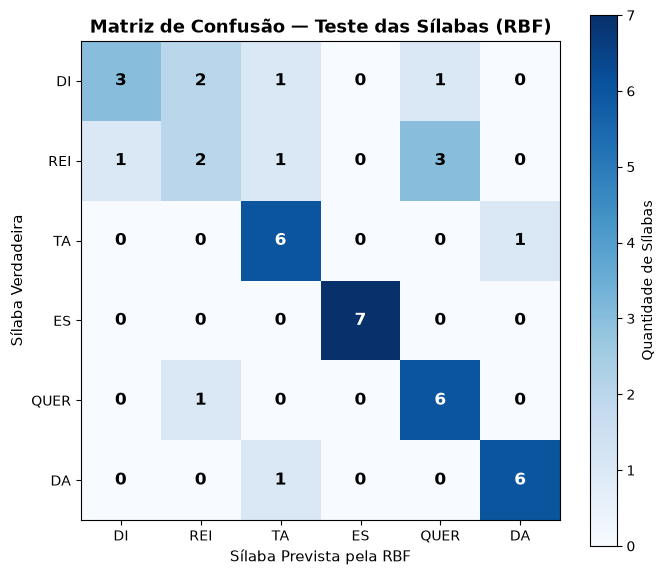

✔ Figura 9 exportada com sucesso para: figuras/rbf_figura9_confusao.png


In [14]:
# ==============================================================================
# FEEDFORWARD NO TESTE E MATRIZ DE CONFUSÃO (FIGURA 9)
# ==============================================================================

# 1. Recuperar parâmetros do melhor modelo treinado
W_final = modelo_final_selecionado["W"]
b_final = modelo_final_selecionado["b"]
centros_final = modelo_final_selecionado["centros"]
sigma_final = modelo_final_selecionado["sigma"]

# 2. Feedforward no conjunto de Teste (Xp_te)
H_te = ativacao_rbf(Xp_te, centros_final, sigma_final)
Z_te = H_te @ W_final + b_final
P_te = softmax(Z_te)
y_pred = np.argmax(P_te, axis=1)

# Acurácia Silábica
acc_teste = 100.0 * np.mean(y_pred == y_te)
print(f"Acurácia da RBF na classificação das 42 sílabas de teste: {acc_teste:.2f}%")

# 3. Construção manual da Matriz de Confusão (apenas com NumPy)
matriz_confusao = np.zeros((6, 6), dtype=int)
for real, prev in zip(y_te, y_pred):
    matriz_confusao[real, prev] += 1

# ------------------------------------------------------------------------------
# Geração da Figura 9
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 6))
cax = ax.imshow(matriz_confusao, interpolation='nearest', cmap=plt.cm.Blues)
fig.colorbar(cax, label="Quantidade de Sílabas")

ax.set_xticks(np.arange(len(CLASSES)))
ax.set_yticks(np.arange(len(CLASSES)))
ax.set_xticklabels(CLASSES)
ax.set_yticklabels(CLASSES)
ax.set_xlabel('Sílaba Prevista pela RBF', fontsize=11)
ax.set_ylabel('Sílaba Verdadeira', fontsize=11)
ax.set_title('Matriz de Confusão — Teste das Sílabas (RBF)', fontsize=13, fontweight='bold')

# Adicionar os valores numéricos no centro dos quadrados
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        cor_texto = "white" if matriz_confusao[i, j] > matriz_confusao.max() / 2 else "black"
        ax.text(j, i, str(matriz_confusao[i, j]), ha="center", va="center", 
                color=cor_texto, fontweight="bold", fontsize=12)

fig.tight_layout()

pasta_figuras = Path("figuras")
caminho_figura = pasta_figuras / "rbf_figura9_confusao.png"
fig.savefig(caminho_figura, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"✔ Figura 9 exportada com sucesso para: {caminho_figura}")

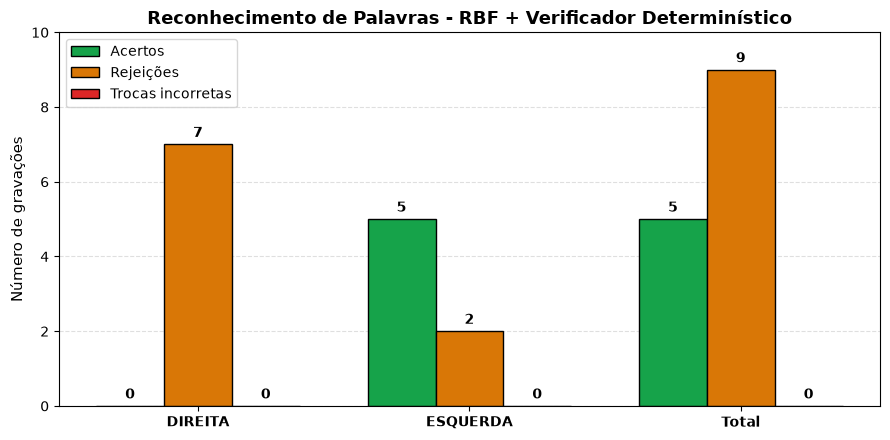

✔ Figura 10 exportada com sucesso para: figuras/rbf_figura10_palavras.png


In [15]:
# ==============================================================================
# VERIFICADOR DE SEQUÊNCIA (IF/ELIF/ELSE) E FIGURA 10
# ==============================================================================

meta_te = dados["teste"]["meta"]

# Agrupamento explícito por gravação de origem e ordenação temporal
gravacoes = {}
for r, p in zip(meta_te, y_pred):
    origem = r["pronuncia_origem"]
    if origem not in gravacoes:
        gravacoes[origem] = {"palavra_real": r["palavra"], "silabas": []}
    gravacoes[origem]["silabas"].append((int(r["ordem"]), p))

# Contadores para as 14 gravações de teste
acertos_direita, rejeicoes_direita, trocas_direita = 0, 0, 0
acertos_esquerda, rejeicoes_esquerda, trocas_esquerda = 0, 0, 0

for origem, dados_g in sorted(gravacoes.items()):
    dados_g["silabas"].sort(key=lambda x: x[0])
    preds_ord = [s[1] for s in dados_g["silabas"]]
    palavra_real = dados_g["palavra_real"]
    
    # Mapeia IDs previstos para nomes de sílabas (-1 representa não classificada)
    s1, s2, s3 = [CLASSES[p] if p >= 0 else "DESCONHECIDO" for p in preds_ord]
    
    # Validação estrutural determinística (DIREITA, ESQUERDA ou REJEIÇÃO)
    if s1 == "DI" and s2 == "REI" and s3 == "TA":
        pred_palavra = "DIREITA"
    elif s1 == "ES" and s2 == "QUER" and s3 == "DA":
        pred_palavra = "ESQUERDA"
    else:
        pred_palavra = "REJEIÇÃO"
        
    if palavra_real == "DIREITA":
        if pred_palavra == "DIREITA":
            acertos_direita += 1
        elif pred_palavra == "ESQUERDA":
            trocas_direita += 1
        else:
            rejeicoes_direita += 1
    elif palavra_real == "ESQUERDA":
        if pred_palavra == "ESQUERDA":
            acertos_esquerda += 1
        elif pred_palavra == "DIREITA":
            trocas_esquerda += 1
        else:
            rejeicoes_esquerda += 1

# Consolidar totais
total_acertos = acertos_direita + acertos_esquerda
total_rejeicoes = rejeicoes_direita + rejeicoes_esquerda
total_trocas = trocas_direita + trocas_esquerda

# ------------------------------------------------------------------------------
# Geração da Figura 10
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 4.5))

labels = ['DIREITA', 'ESQUERDA', 'Total']
acertos = [acertos_direita, acertos_esquerda, total_acertos]
rejeicoes = [rejeicoes_direita, rejeicoes_esquerda, total_rejeicoes]
trocas = [trocas_direita, trocas_esquerda, total_trocas]

x = np.arange(len(labels))
width = 0.25

rects1 = ax.bar(x - width, acertos, width, label='Acertos', color='#16a34a', edgecolor='black')
rects2 = ax.bar(x, rejeicoes, width, label='Rejeições', color='#d97706', edgecolor='black')
rects3 = ax.bar(x + width, trocas, width, label='Trocas incorretas', color='#dc2626', edgecolor='black')

ax.set_ylabel('Número de gravações', fontsize=11)
ax.set_title('Reconhecimento de Palavras - RBF + Verificador Determinístico', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontweight='bold')
ax.set_yticks(np.arange(0, 11, 2))
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

def autolabel(rects):
    """Adiciona rótulos acima das barras."""
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # Deslocamento vertical
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)

fig.tight_layout()

caminho_figura = pasta_figuras / "rbf_figura10_palavras.png"
fig.savefig(caminho_figura, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"✔ Figura 10 exportada com sucesso para: {caminho_figura}")


## 8. Encerramento e Verificação de Arquivos

**Considerações Finais e Interpretação Metodológica:**
A implementação da Rede RBF do zero combina o algoritmo K-Means na camada oculta (para posicionamento dos campos receptivos radiais locais) com o Gradiente Descendente (Adam) na camada de saída. Esta arquitetura híbrida permite desacoplar a representação espacial não supervisionada da otimização linear supervisionada da saída.

Na avaliação retrospectiva no conjunto de teste, o modelo selecionado tem sua generalização avaliada tanto no nível de sílabas individuais (matriz de confusão) quanto no nível das sequências temporais de palavras, através do verificador determinístico estrutural. Como o verificador exige a correspondência exata das três sílabas consecutivas, eventuais confusões pontuais entre fonemas com envelopes espectrais próximos resultam em rejeições seguras, prevenindo trocas incorretas (falsos positivos).

**Conclusão e Limitações:**
O uso de funções de base radial locais oferece interpretabilidade geométrica direta aos agrupamentos acústicos, apresentando sensibilidade à escolha conjunta da capacidade ($K$), da dispersão radial ($\sigma$) e da taxa de convergência ($lr$). Os resultados experimentais definitivos serão consolidados após a execução completa dos treinamentos.

Abaixo, o script de auditoria para confirmar que todas as figuras geradas (incluindo as combinações do Grupo E) estão prontas para o relatório.


In [16]:
# ==============================================================================
# AUDITORIA DAS 11 FIGURAS EXPORTADAS PARA O RELATÓRIO
# ==============================================================================
from pathlib import Path
import os

pasta = Path("figuras")
figuras_esperadas = [
    "rbf_figura1_fft.png",
    "rbf_figura2_arquitetura.png",
    "rbf_figura3_treino_inicial.png",
    "rbf_figura4_centros.png",
    "rbf_figura5_sigma.png",
    "rbf_figura6_lr.png",
    "rbf_figura7_regularizacao.png",
    "rbf_grupo_e_combinacoes.png",
    "rbf_figura8_comparacao_final.png",
    "rbf_figura9_confusao.png",
    "rbf_figura10_palavras.png"
]

print(f"Verificando arquivos em '{pasta.absolute()}'...\n")

todas_encontradas = True
for fig in figuras_esperadas:
    caminho = pasta / fig
    if caminho.exists():
        tamanho_kb = os.path.getsize(caminho) / 1024
        print(f"[ OK ] {fig:<35} ({tamanho_kb:.1f} KB)")
    else:
        print(f"[ PENDENTE / NÃO EXECUTADO ] {fig}")
        todas_encontradas = False

if todas_encontradas:
    print("\nAuditoria concluída: Todas as 11 imagens foram geradas com sucesso.")
else:
    print("\nAuditoria: Arquivos verificados. Execute o treinamento para atualizar as imagens pendentes.")


Verificando arquivos em '/home/soaresgaab/Documentos/Mestrado UFMA/Disciplinas/Redes Neurais/Pipeline/figuras'...

[ OK ] rbf_figura1_fft.png                 (102.9 KB)
[ OK ] rbf_figura2_arquitetura.png         (82.3 KB)
[ OK ] rbf_figura3_treino_inicial.png      (215.0 KB)
[ OK ] rbf_figura4_centros.png             (211.2 KB)
[ OK ] rbf_figura5_sigma.png               (206.0 KB)
[ OK ] rbf_figura6_lr.png                  (197.2 KB)
[ OK ] rbf_figura7_regularizacao.png       (168.9 KB)
[ OK ] rbf_grupo_e_combinacoes.png         (228.1 KB)
[ OK ] rbf_figura8_comparacao_final.png    (197.4 KB)
[ OK ] rbf_figura9_confusao.png            (137.4 KB)
[ OK ] rbf_figura10_palavras.png           (98.2 KB)

Auditoria concluída: Todas as 11 imagens foram geradas com sucesso.


In [17]:
print("=====================================================")
print("  PIPELINE DA REDE RBF CONCLUÍDO COM SUCESSO! 🚀")
print("=====================================================")

  PIPELINE DA REDE RBF CONCLUÍDO COM SUCESSO! 🚀
